# 高维数据与维度灾难
所有实验使用真实白血病数据。先填写预测，再运行。

In [ ]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
HERE=Path.cwd().resolve()
REPO=next((p for p in [HERE,*HERE.parents] if (p/"assignments/hw03/resources/scripts/experiments.py").exists()),None)
if REPO is None: raise RuntimeError("请在课程仓库内运行HW03 Notebook")
BASE=REPO/"assignments/hw03/resources"
sys.path.insert(0,str(BASE/"scripts"))
import experiments as lab
OUT=HERE/"student-results"
OUT.mkdir(exist_ok=True)

## T1 读取真实数据

In [12]:
df,X,names=lab.load_real()
print("n,p",X.shape,"p/n",X.shape[1]/X.shape[0])
display(df.groupby(["original_split","diagnosis"]).size().rename("n").to_frame())
display(df.iloc[:3,:6])

n,p (72, 7129) p/n 99.01388888888889


n
original_split diagnosis    
test           ALL        20
               AML        14
train          ALL        27
               AML        11

,sample_id,original_split,diagnosis,AFFX-BioB-5_at,AFFX-BioB-M_at,AFFX-BioB-3_at
0,G001,train,ALL,-214,-153,-58
1,G002,train,ALL,-139,-73,-1
2,G003,train,ALL,-76,-49,-307


## T2 实验A 距离
先写预测。诊断只在图中事后着色。

,42,7,2026
0,X51730_at,M60052_at,U26727_at
1,U13616_at,HG2600-HT2696_at,M34516_r_at
2,X97261_at,X04741_at,U59831_rna1_s_at


,seed,p,mean,sd,cv,near_median,far_median,gap_median,r_median,zero_nearest
0,42,2,1.268799,1.564125,1.232761,0.067518,7.903008,7.860022,115.451967,0
1,42,3,1.810146,1.675672,0.925711,0.234539,8.763866,8.482727,35.998344,0
2,42,10,4.215053,1.585882,0.376243,1.797615,9.655803,7.559482,4.318717,0
3,42,100,13.916946,3.022502,0.217181,9.669579,21.461561,12.011417,1.199352,0
4,42,1000,44.181567,8.726863,0.197523,33.067257,66.515369,34.236792,1.048856,0
5,42,7129,118.196488,22.099935,0.186976,87.931134,174.900278,87.138000,0.966904,0


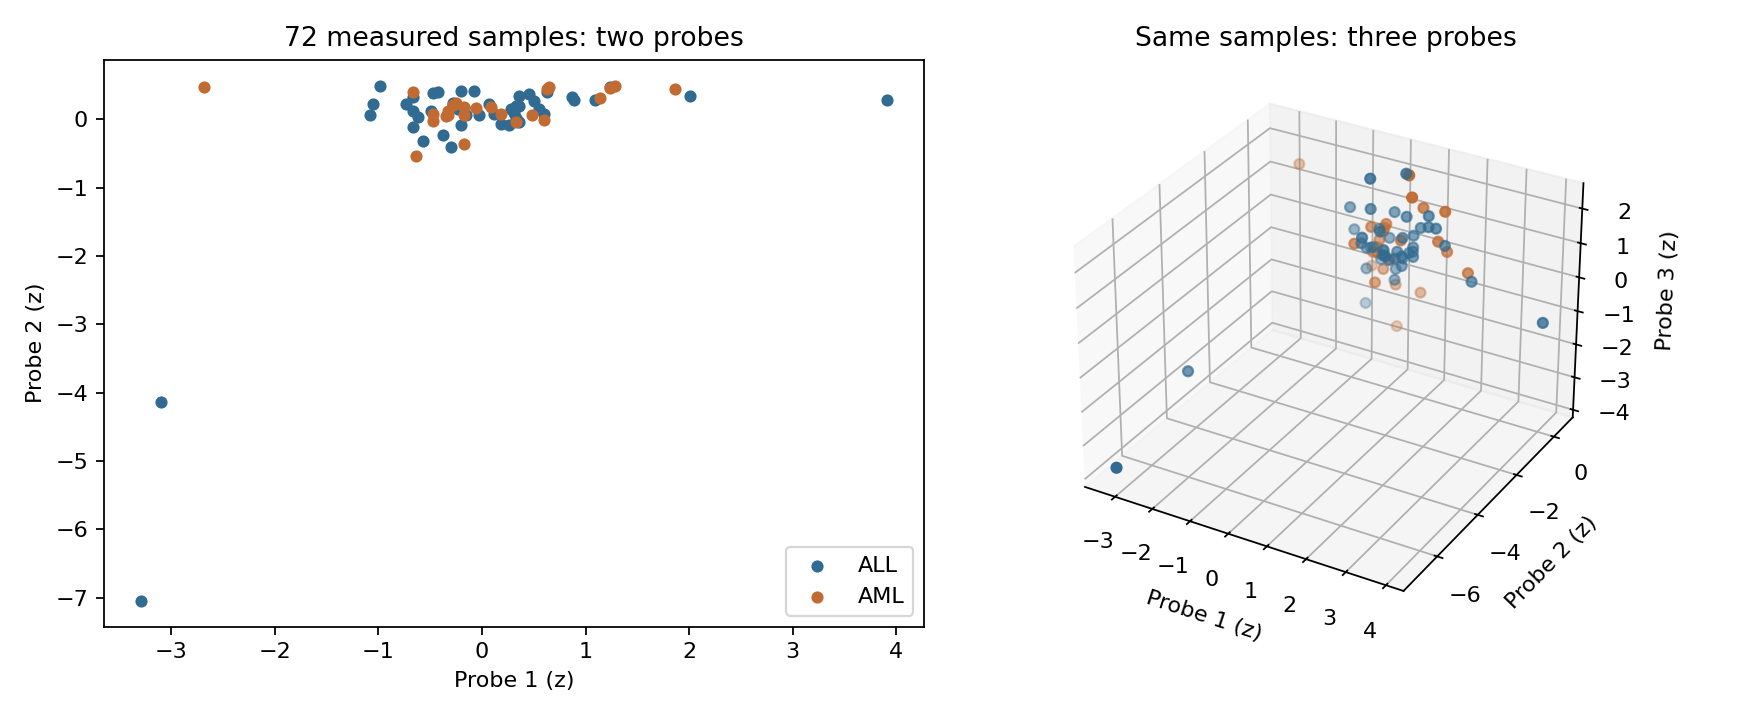

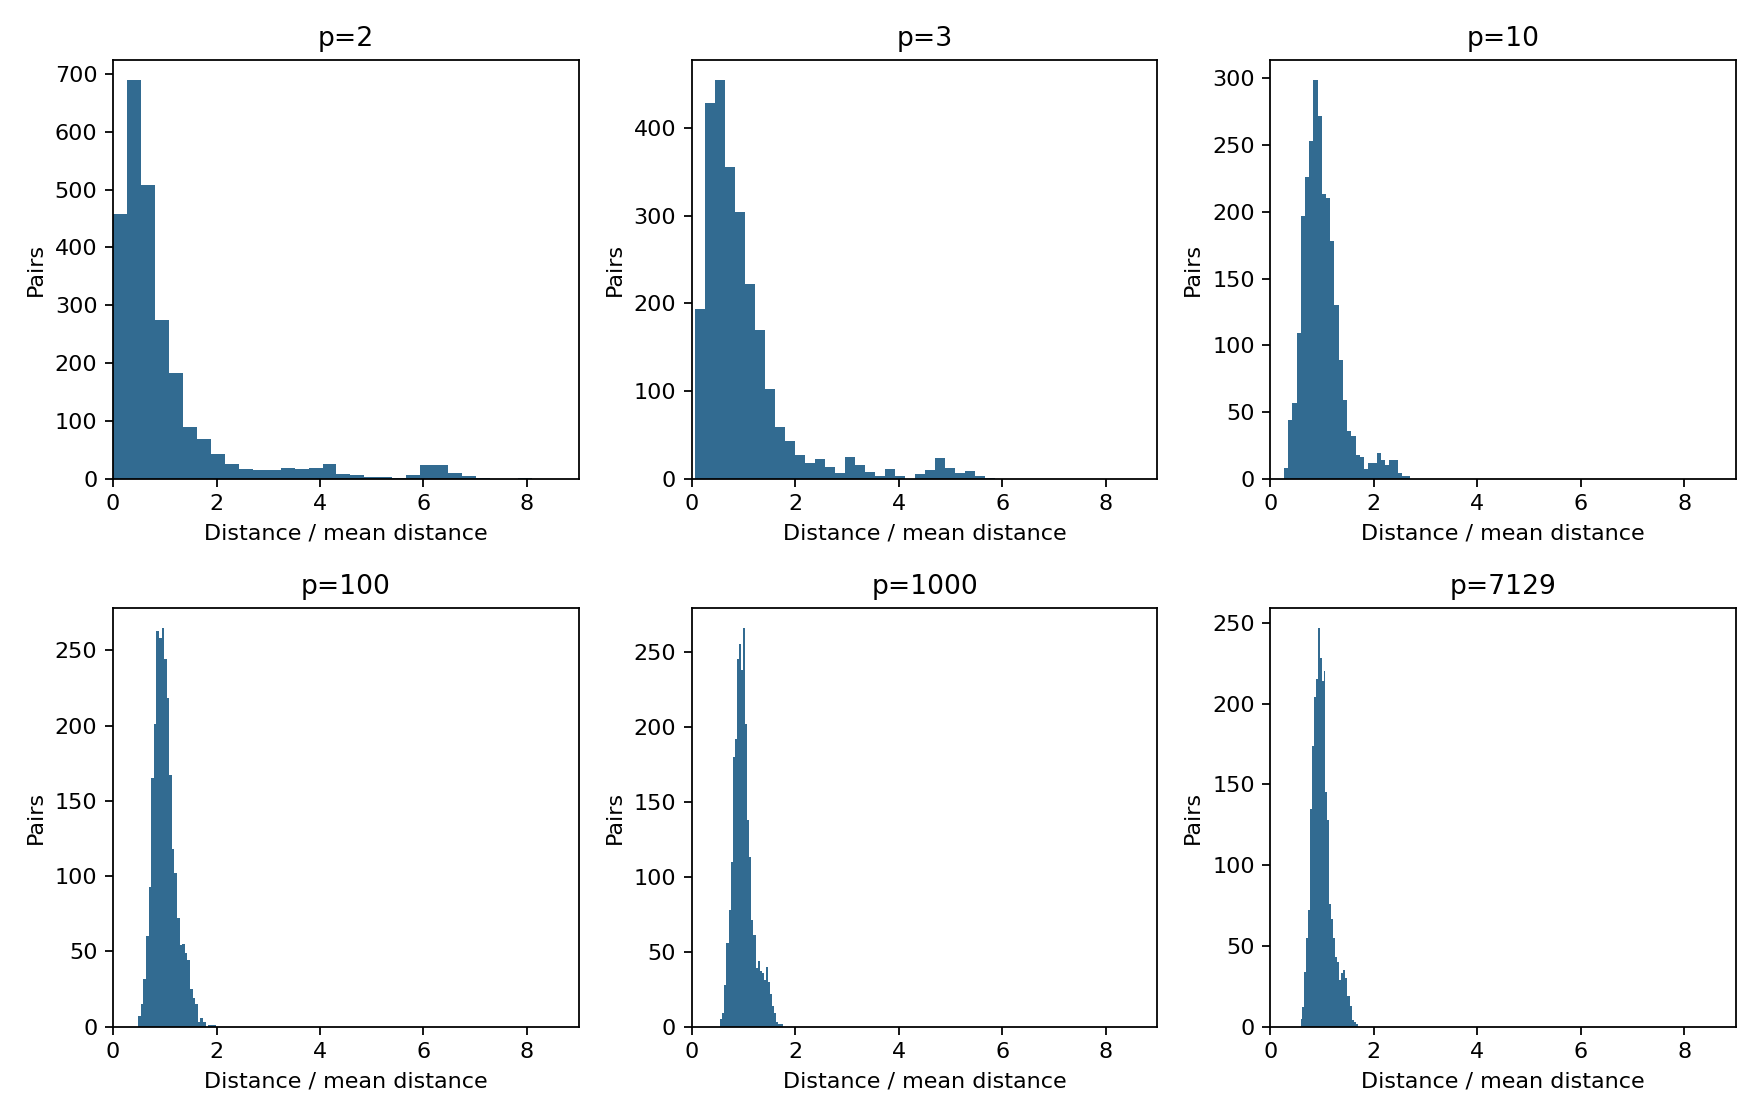

In [13]:
a=lab.experiment_a(OUT)
display(pd.read_csv(OUT/"A-probe-orders.csv").head(3))
display(a[a.seed.eq(42)])
display(Image(filename=str(OUT/"A-scatter-2D-3D.png")))
display(Image(filename=str(OUT/"A-distance-distributions.png")))

## T3 近远邻与选列

In [14]:
near=pd.read_csv(OUT/"A-neighbors-seed42.csv")
display(near[near.sample_id.eq("G001") & near.p.isin([2,7129])])
display(a[["seed","p","cv","r_median","gap_median"]])

,sample_id,p,near,far,R
0,G001,2,0.049192,7.954082,160.695864
360,G001,7129,93.695760,156.146171,0.666523


,seed,p,cv,r_median,gap_median
0,42,2,1.232761,115.451967,7.860022
1,42,3,0.925711,35.998344,8.482727
2,42,10,0.376243,4.318717,7.559482
3,42,100,0.217181,1.199352,12.011417
4,42,1000,0.197523,1.048856,34.236792
5,42,7129,0.186976,0.966904,87.138000
6,7,2,0.614496,23.676032,4.234162
7,7,3,0.539419,10.198094,4.667459
8,7,10,0.301309,2.400987,5.317424
9,7,100,0.214420,1.286433,13.079189


## T4 实验B 先看训练
先记录训练分数能支持什么。

In [15]:
b,cv=lab.experiment_b(OUT)
display(b[["p","train_ba"]])

,p,train_ba
0,2,1.0
1,10,1.0
2,100,1.0
3,1000,1.0
4,7129,1.0


记录判断后再看测试。

,p,train_ba,test_ba,ALL_correct,AML_correct
0,2,1.0,0.496429,17,2
1,10,1.0,0.578571,16,5
2,100,1.0,0.653571,19,5
3,1000,1.0,0.725000,19,7
4,7129,1.0,0.760714,19,8


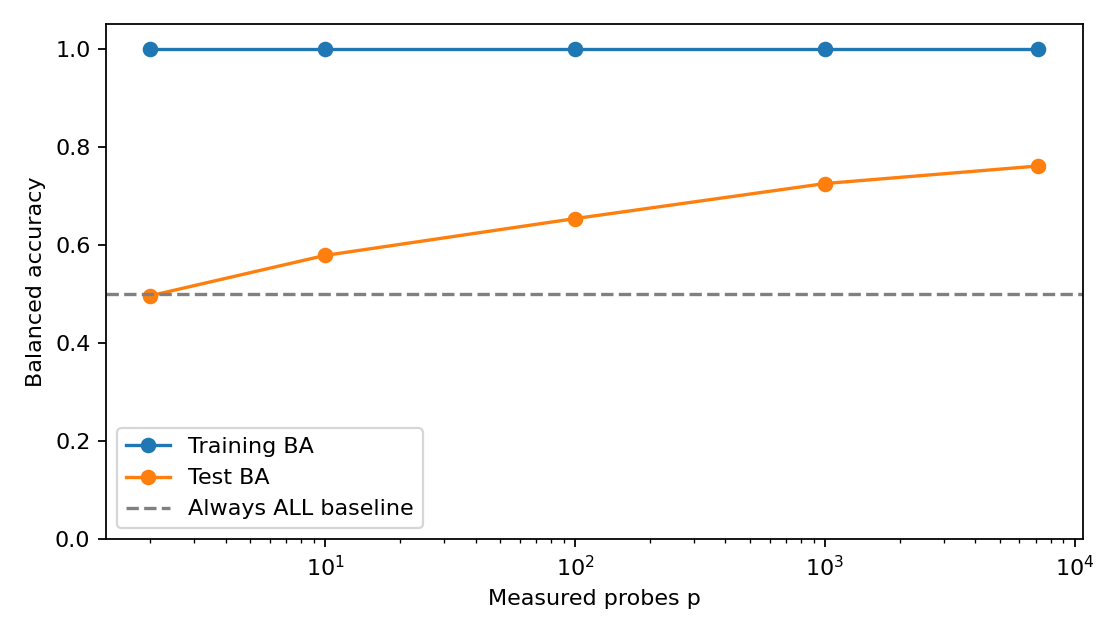

恒预测ALL的BA基线0.5


In [16]:
display(b)
display(Image(filename=str(OUT/"B-generalization.png")))
print("恒预测ALL的BA基线0.5")

## T5 退出卡
在工作单完成理论计算、流程修复与结论。

## H1 验证与筛选稳定性

In [19]:
display(cv.groupby("method").validation_ba.agg(["mean","min","max","std"]))
display(cv)
stability=pd.read_csv(OUT/"B-selection-stability.csv")
display(stability.jaccard.agg(["median","min","max"]))
import importlib.metadata
print({n:importlib.metadata.version(n) for n in ["numpy","pandas","scipy","scikit-learn","matplotlib"]})

,mean,min,max,std
method,,,,
all7129,0.844136,0.694444,1.0,0.106858
select20,0.885802,0.750000,1.0,0.083269


,repeat,fold,method,train_n,validation_n,train_ba,validation_ba
0,1,1,all7129,25,13,1.0,0.819444
1,1,1,select20,25,13,1.0,0.875000
2,1,2,all7129,25,13,1.0,0.875000
3,1,2,select20,25,13,1.0,0.944444
4,1,3,all7129,26,12,1.0,0.833333
5,1,3,select20,26,12,1.0,1.000000
6,2,1,all7129,25,13,1.0,0.750000
7,2,1,select20,25,13,1.0,0.750000
8,2,2,all7129,25,13,1.0,0.875000
9,2,2,select20,25,13,1.0,0.819444


median    0.270161
min       0.142857
max       0.428571
Name: jaccard, dtype: float64

{'numpy': '2.2.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8'}


## 我的解释
填写主张、距离证据、泛化证据、推理和边界，记录代码或参数改动。
主张：
特征越多并不必然让模型更好。增加特征可能带来真正有用的疾病信息，从而提高对新样本的预测；但也可能加入噪声、重复信息或无关信息，使高维空间中的距离更集中、模型更容易受到小样本偶然差异的影响。因此，应以独立验证表现判断，而不能只看训练分数或特征数量。

距离证据：
固定72份样本、沿 seed=42 的探针顺序增加特征数时，样本对平均欧氏距离从 \(p=2\) 的1.268799增至 \(p=7129\) 的118.196488；但距离CV从1.232761降至0.186976。对G001，最近距离与最远距离的相对差异  
\[
R=(d_{\max}-d_{\min})/d_{\min}
\]
从 \(p=2\) 的160.695864降至 \(p=7129\) 的0.666523。说明绝对距离可以增加，但“近”和“远”的相对区别变弱，这会削弱依赖距离的近邻分类或聚类的辨别能力。

泛化证据：
1近邻模型在训练集的BA对所有 \(p=2,10,100,1000,7129\) 都是1.0，但测试BA从0.496429、0.578571、0.653571、0.725000上升至0.760714，且高于恒预测ALL的基线BA=0.5。这说明本次加入更多探针没有导致测试表现变差，反而可能加入了有用信息；但训练BA满分不能证明泛化良好，因为训练样本可能把自己当作最近邻。训练集内3折、3重复验证中，全部7,129特征的验证BA均值为0.844136，折内筛选20项后为0.885802；不过筛选集合的Jaccard中位数仅0.270161，提示被选探针不稳定。

推理：
高维导致距离相对集中，不代表模型一定不能分类；如果新增特征包含与ALL/AML真实相关的表达信息，1近邻仍可能在测试集上受益。本实验中测试BA上升支持“新增特征整体提供了部分信息”，但较低的Jaccard说明具体哪些探针最重要不能轻易下结论。性能改善也可能受这一次训练/测试划分、探针相关性和样本偶然差异影响。

边界：
结论只适用于这72份样本、固定的原始训练38例和测试34例、seed=42、逐列z-score、欧氏距离与1近邻分类器。72份样本不能代表所有白血病患者；7,129个探针也不等于7,129份独立生物信息。不能从预测关联推断某个探针导致疾病，更不能直接证明临床有效性。应在训练折内完成标准化和特征选择，并在独立外部患者队列中预先固定模型后再验证。

代码或参数改动记录：
未改变原始表达值、诊断标签或训练/测试划分。距离实验使用 seed=42 固定探针列顺序，并比较 \(p=2,3,10,100,1000,7129\)；分类实验比较 \(p=2,10,100,1000,7129\)，固定 StandardScaler 与1近邻。重复交叉验证比较全部7,129个探针和“每个训练折内按ANOVA F分数筛选20个探针”两种方案。